# CAT-Net 사전학습 모델 평가

- 작성자: kimjaehak
- 상태: 작성 중
- 기준 실험: 003 CAT-Net 단일 이미지 검증
- 목적: 공통 함수로 사전학습 모델을 실행하고 평가 대상 전체의 성능을 확인함.
- 평가 대상: AutoSplice test(JPEG 100·90·75), CocoGlide 전체
- 평가 지표: 조작 이미지의 Pixel F1·IoU, 정상 이미지의 픽셀 오탐률
- 데이터셋·JPEG 품질별 결과를 구분함.
- 학습과 파인튜닝은 수행하지 않으며, 테스트 점수로 설정을 선택하지 않음.
- PNG 입력 처리와 세부 평가 조건은 추론 전에 기록함.

In [4]:
%pip install numpy Pillow pyjpegio yacs PyYAML torch-dct opencv-python tqdm matplotlib pandas


In [5]:
import jpegio
import yacs.config
import yaml
import torch_dct
import cv2
import tqdm
import matplotlib.pyplot as plt
import pandas as pd

import platform
from importlib.metadata import version, PackageNotFoundError

import torch

print("Python:", platform.python_version())

packages = ("torch", "torchvision", "numpy", "Pillow", "pyjpegio", "yacs", "PyYAML", "torch-dct", "opencv-python", "tqdm", "matplotlib", "pandas")

for package in packages:
    try:
        print(f"{package}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package}: 설치되지 않음.")

print("PyTorch CUDA:", torch.version.cuda)
print("GPU 사용 가능:", torch.cuda.is_available())

gpu = torch.cuda.get_device_properties(0)
print("GPU:", gpu.name)
print("GPU 전체 메모리(GiB):", round(gpu.total_memory / 1024**3, 2))

print("jpegio 경로:", jpegio.__file__)
print("JPEG 읽기 함수:", callable(jpegio.read))

Python: 3.13.16
torch: 2.14.1+cu130
torchvision: 0.29.1+cu130
numpy: 2.4.6
Pillow: 11.3.0
pyjpegio: 0.3.0
yacs: 0.1.8
PyYAML: 6.0.3
torch-dct: 0.1.6
opencv-python: 5.0.0.93
tqdm: 4.67.3
matplotlib: 3.10.0
pandas: 2.2.3
PyTorch CUDA: 13.0
GPU 사용 가능: True
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition
GPU 전체 메모리(GiB): 94.97
jpegio 경로: /usr/local/lib/python3.13/dist-packages/jpegio/__init__.py
JPEG 읽기 함수: True


In [6]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [7]:
from pathlib import Path
import sys

shared_root = Path("/content/drive/MyDrive/AI_Forensics")
project_root = shared_root / "project"
work_root = Path("/content")

code_dir = work_root / "CAT-Net"
weight_source = project_root / "models/pretrained/catnet/CAT_full_v2.pth.tar"
weight_path = work_root / "CAT_full_v2.pth.tar"

archive_paths = {
    "AutoSplice": shared_root / "datasets/AutoSplice/AutoSplice.zip",
    "CocoGlide": shared_root / "datasets/CocoGlide.zip",
}

data_root = work_root / "datasets"
split_path = project_root / "scripts/splits/autosplice_seed42.csv"


In [8]:
sys.path.insert(0, str(project_root))
from scripts import catnet, datasets, preprocessing, evaluation

## 공통함수를 이용한 flow

### 모델 로드

In [9]:
# CAT-NET 경로 설정
code_dir = catnet.prepare_code(code_dir)
weight_path = catnet.prepare_weights(weight_source, weight_path)

#모델 로드
detector = catnet.CatNetDetector.from_pretrained(code_dir, weight_path, device="cuda")
for key, value in detector.info.items():
    print(f"{key}: {value}")


print("device:", next(detector.model.parameters()).device)
print("is test mode?:", not detector.model.training)
print("로드 -완-")

공식 코드: /content/CAT-Net
코드 커밋: 5eb85900b0e72423c95a8d41bc835b86c8671f8a
가중치 복사·해시 확인 완료: /content/CAT_full_v2.pth.tar
code_commit: 5eb85900b0e72423c95a8d41bc835b86c8671f8a
code_dir: /content/CAT-Net
weight_path: /content/CAT_full_v2.pth.tar
weight_sha256: f82aaafdd1142775231feedcea0bb7027f7370561d9e8d107465454001865989
weight_bytes: 915503873
epoch: 196
parameters: 114263810
device: cuda
wrapper_sha256: 04d2d6561caf27ae83ccff844adf2b71c02d48470a37359d268f2ee8e217c889
resize: bilinear
align_corners: False
device: cuda:0
is test mode?: True
로드 -완-


### 데이터 로드

In [10]:
import pandas as pd
from IPython.display import display

archive_hashes = {
    "AutoSplice": "0d94e2df6842f44c11e21ee207707c49fd9717ec89048bd6f28fc1e07c4a5e36",
    "CocoGlide": "fc848643ad0a81010ba2a6ab8c055762782f54e4fb9e407210dbfe1c3b538af9",
}
extract_paths = {
    "AutoSplice": data_root,
    "CocoGlide": data_root / "CocoGlide",
}

for name, source in archive_paths.items():
    datasets.prepare_dataset_zip(source, work_root / f"{name}.zip", extract_paths[name], archive_hashes[name])
    print("ZIP 기준 SHA-256:", name, archive_hashes[name])

AutoSplice ZIP SHA-256 확인 및 압축 해제 완료
ZIP 기준 SHA-256: AutoSplice 0d94e2df6842f44c11e21ee207707c49fd9717ec89048bd6f28fc1e07c4a5e36
CocoGlide ZIP SHA-256 확인 및 압축 해제 완료
ZIP 기준 SHA-256: CocoGlide fc848643ad0a81010ba2a6ab8c055762782f54e4fb9e407210dbfe1c3b538af9


In [11]:
eval_records = []

for quality in (100, 90, 75):
    records = datasets.autosplice_records(data_root / "AutoSplice", split_path, quality=quality)

    for record in records:
        if record["split"] != "test":
            continue
        if record["kind"] == "normal" and quality != 100:
            continue

        variant = "original" if record["kind"] == "normal" else f"JPEG{quality}"
        eval_records.append(dict(record, variant=variant))

records = datasets.cocoglide_records(data_root / "CocoGlide")

for record in records:
    eval_records.append(dict(record, variant="PNG"))

eval_table = pd.DataFrame(eval_records)

if eval_table["image_path"].duplicated().any():
    raise ValueError("평가 목록에 같은 이미지 경로가 중복되지 않아야 함.")

summary = eval_table.groupby(["dataset", "split", "variant", "kind"]).size().reset_index(name="images")

display(summary)
print("전체 평가 이미지 수:", len(eval_records))


,dataset,split,variant,kind,images
0,AutoSplice,test,JPEG100,manipulated,335
1,AutoSplice,test,JPEG75,manipulated,335
2,AutoSplice,test,JPEG90,manipulated,335
3,AutoSplice,test,original,normal,228
4,CocoGlide,external_test,PNG,manipulated,512
5,CocoGlide,external_test,PNG,normal,512


전체 평가 이미지 수: 2257


In [12]:
from PIL import Image, features
from tqdm.auto import tqdm

jpeg_quality = 100
jpeg_subsampling = 0

cocoglide_root = data_root / "CocoGlide"
jpeg_root = work_root / "catnet_inputs" / "CocoGlide_JPEG100_444"

input_records = []
converted_count = 0

for record in tqdm(eval_records, desc="CAT-Net 입력 준비"):
    source = record["image_path"]
    input_path = source
    conversion = "none"

    if record["dataset"] == "CocoGlide":
        relative = source.relative_to(cocoglide_root)
        input_path = (jpeg_root / relative).with_suffix(".jpg")
        input_path.parent.mkdir(parents=True, exist_ok=True)

        with Image.open(source) as image:
            if image.format != "PNG":
                raise ValueError(f"png 가 아니여요: {source}")

            original_size = image.size
            rgb = image.convert("RGB")
            rgb.save(input_path, format="JPEG", quality=jpeg_quality, subsampling=jpeg_subsampling)

        with Image.open(input_path) as image:
            image.load()
            if image.format != "JPEG" or image.size != original_size:
                raise ValueError(f"변환 형식과 원본 크기가 일치해야 함: {input_path}")

        conversion = "PNG_to_JPEG100_444"
        converted_count += 1

    input_records.append(dict(record, input_path=input_path, input_conversion=conversion))

if converted_count != 1024 or len(input_records) != len(eval_records):
    raise ValueError("CocoGlide 변환 수 안맞음")

input_table = pd.DataFrame(input_records)
summary = input_table.groupby(["dataset", "variant", "kind", "input_conversion"]).size().reset_index(name="images")

display(summary)
print("JPEG 변환 조건:", dict(quality=jpeg_quality, subsampling=jpeg_subsampling))
print("JPEG 라이브러리:", features.version_codec("jpg"))
print("CocoGlide 변환 이미지 수:", converted_count)
print("전체 평가 이미지 수:", len(input_records))
print("변환 파일 위치:", jpeg_root)

CAT-Net 입력 준비:   0%|          | 0/2257 [00:00<?, ?it/s]

,dataset,variant,kind,input_conversion,images
0,AutoSplice,JPEG100,manipulated,none,335
1,AutoSplice,JPEG75,manipulated,none,335
2,AutoSplice,JPEG90,manipulated,none,335
3,AutoSplice,original,normal,none,228
4,CocoGlide,PNG,manipulated,PNG_to_JPEG100_444,512
5,CocoGlide,PNG,normal,PNG_to_JPEG100_444,512


JPEG 변환 조건: {'quality': 100, 'subsampling': 0}
JPEG 라이브러리: 6.2
CocoGlide 변환 이미지 수: 1024
전체 평가 이미지 수: 2257
변환 파일 위치: /content/catnet_inputs/CocoGlide_JPEG100_444


### coco glide 한 장을 예시로 해보자.

In [13]:
import numpy as np

sample = next(r for r in input_records if r["dataset"] == "CocoGlide" and r["kind"] == "manipulated")
rgb = preprocessing.load_rgb(sample["image_path"])
mask = preprocessing.load_binary_mask(sample["mask_path"], foreground_value=255)

input_tensor, qtable, original_size = catnet.prepare_input(sample["input_path"], code_dir)

print("원본 이미지:", sample["image_path"])
print("모델 입력 파일:", sample["input_path"])
print("입력 변환:", sample["input_conversion"])
print("원본 RGB:", rgb.shape)
print("정답 마스크:", mask.shape)
print("JPEG 원본 크기(H, W):", original_size)
print("RGB+DCT 입력:", tuple(input_tensor.shape), input_tensor.dtype)
print("양자화 테이블:", tuple(qtable.shape), qtable.dtype)

원본 이미지: /content/datasets/CocoGlide/fake/glide_inpainting_val2017_114871_up.png
모델 입력 파일: /content/catnet_inputs/CocoGlide_JPEG100_444/fake/glide_inpainting_val2017_114871_up.jpg
입력 변환: PNG_to_JPEG100_444
원본 RGB: (256, 256, 3)
정답 마스크: (256, 256)
JPEG 원본 크기(H, W): (256, 256)
RGB+DCT 입력: (24, 256, 256) torch.float32
양자화 테이블: (1, 8, 8) torch.float32


/content/CAT-Net/Splicing/data/AbstractDataset.py:163: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  t_DCT_coef = torch.tensor(DCT_coef, dtype=torch.float)  # final (but used below)


In [14]:
probability = detector.predict_proba(sample["input_path"])

print("예측 확률:", probability.shape, probability.dtype)
print("확률 범위:", float(probability.min()), float(probability.max()))

예측 확률: (256, 256) float32
확률 범위: 0.00748117920011282 0.3869096636772156


/content/CAT-Net/lib/models/network_CAT.py:543: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  x1 = F.upsample(x[1], size=(x0_h, x0_w), mode='bilinear')
/content/CAT-Net/lib/models/network_CAT.py:544: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  x2 = F.upsample(x[2], size=(x0_h, x0_w), mode='bilinear')
/content/CAT-Net/lib/models/network_CAT.py:545: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  x3 = F.upsample(x[3], size=(x0_h, x0_w), mode='bilinear')


별로 마음에 드는 결과는 아닌듯?
조작되지 않았다고 나오는 거니까

### 전체 이미지 확인

In [15]:
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

threshold = 0.5
mask_foreground = 255

evaluation_rows = []
results_df = None
metrics_summary = None

print("임계값:", threshold)
print("마스크 전경값:", mask_foreground)
print("평가 해상도: 원본 크기")
print("집계 방식: 이미지별 점수의 산술평균")

for record in tqdm(input_records, desc="CAT-Net 전체 평가"):
    try:
        with Image.open(record["image_path"]) as image:
            width, height = image.size

        if record["kind"] == "normal":
            mask = np.zeros((height, width), dtype=np.uint8)
        elif record["kind"] == "manipulated":
            mask = preprocessing.load_binary_mask(record["mask_path"], foreground_value=mask_foreground)
            if not mask.any():
                raise ValueError("조작 이미지의 정답 마스크에 전경이 있어야 함.")
        else:
            raise ValueError("이미지 종류는 normal 또는 manipulated여야 함.")

        if mask.shape != (height, width):
            raise ValueError("원본 이미지와 정답 마스크의 크기가 일치해야 함.")

        probability = detector.predict_proba(record["input_path"])
        prediction = (probability >= threshold).astype(np.uint8)

        tp, fp, fn, tn = evaluation.confusion_counts(mask, prediction)

        f1 = iou_score = fpr = None

        if record["kind"] == "manipulated":
            f1 = evaluation.pixel_f1(tp, fp, fn)
            iou_score = evaluation.iou(tp, fp, fn)
        else:
            fpr = evaluation.false_positive_rate(fp, tn)

        evaluation_rows.append(dict(
            record, threshold=threshold, height=height, width=width,
            tp=tp, fp=fp, fn=fn, tn=tn, f1=f1, iou=iou_score, fpr=fpr
        ))

    except Exception:
        print("평가 중단 이미지:", record["image_path"])
        print("완료한 이미지 수:", len(evaluation_rows))
        raise



임계값: 0.5
마스크 전경값: 255
평가 해상도: 원본 크기
집계 방식: 이미지별 점수의 산술평균


CAT-Net 전체 평가:   0%|          | 0/2257 [00:00<?, ?it/s]

In [19]:
results_df = pd.DataFrame(evaluation_rows)

group_columns = ["dataset", "split", "variant", "input_conversion", "kind"]

metrics_summary = results_df.groupby(group_columns).agg(
    images=("image_path", "size"),
    pixel_f1=("f1", "mean"),
    iou=("iou", "mean"),
    false_positive_rate=("fpr", "mean")
).reset_index()

display(metrics_summary)

,dataset,split,variant,input_conversion,kind,images,pixel_f1,iou,false_positive_rate
0,AutoSplice,test,JPEG100,none,manipulated,335,0.881532,0.804299,NaN
1,AutoSplice,test,JPEG75,none,manipulated,335,0.402828,0.320014,NaN
2,AutoSplice,test,JPEG90,none,manipulated,335,0.804874,0.717161,NaN
3,AutoSplice,test,original,none,normal,228,NaN,NaN,0.146428
4,CocoGlide,external_test,PNG,PNG_to_JPEG100_444,manipulated,512,0.363874,0.287961,NaN
5,CocoGlide,external_test,PNG,PNG_to_JPEG100_444,normal,512,NaN,NaN,0.166143


## 몇개 정도 결과 출력해보자

/content/CAT-Net/lib/models/network_CAT.py:543: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  x1 = F.upsample(x[1], size=(x0_h, x0_w), mode='bilinear')
/content/CAT-Net/lib/models/network_CAT.py:544: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  x2 = F.upsample(x[2], size=(x0_h, x0_w), mode='bilinear')
/content/CAT-Net/lib/models/network_CAT.py:545: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  x3 = F.upsample(x[3], size=(x0_h, x0_w), mode='bilinear')


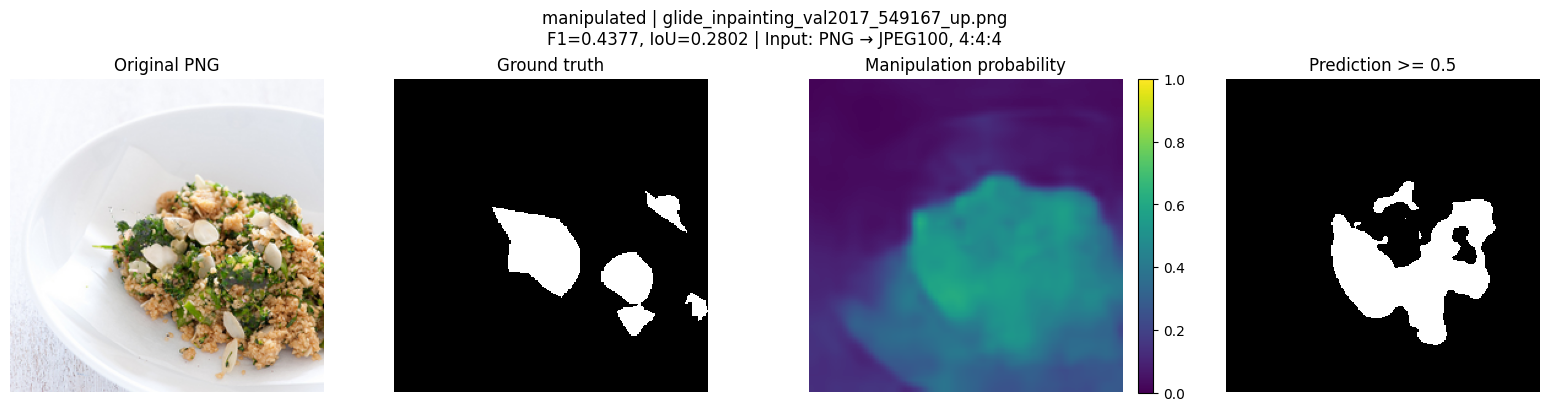

TP·FP·FN·TN: 3050 5302 2534 54650
최대 조작 확률: 0.6181424856185913
예측 조작 영역 비율: 0.12744140625


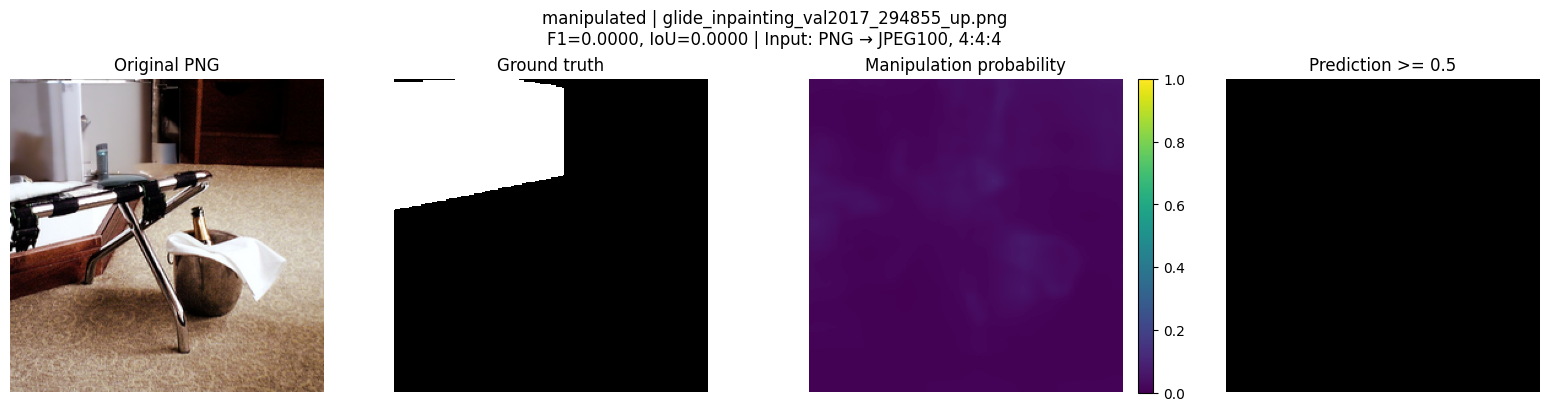

TP·FP·FN·TN: 0 0 12658 52878
최대 조작 확률: 0.07570496946573257
예측 조작 영역 비율: 0.0


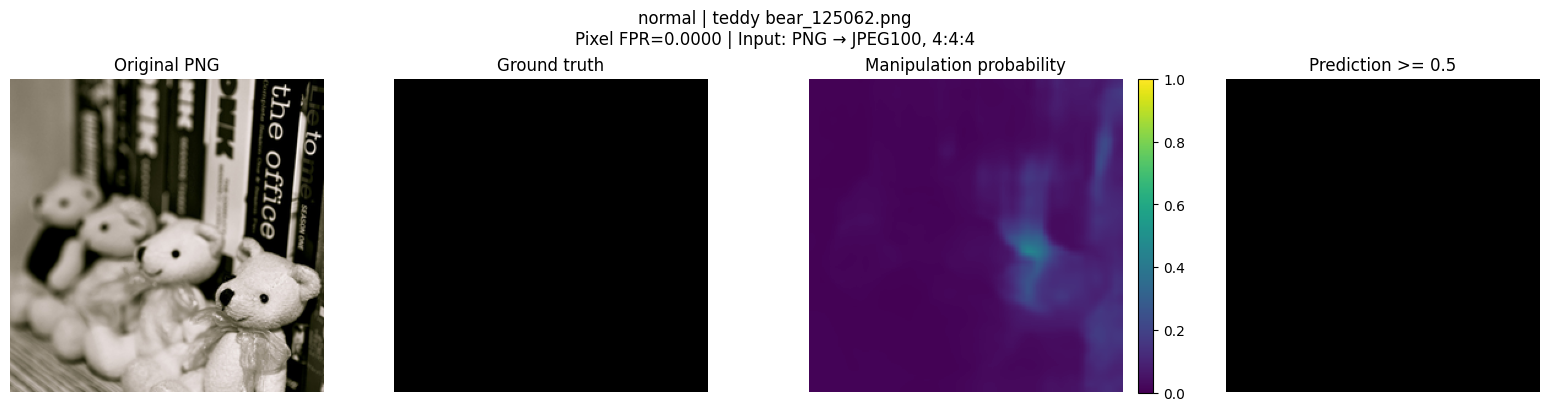

TP·FP·FN·TN: 0 0 0 65536
최대 조작 확률: 0.45446962118148804
예측 조작 영역 비율: 0.0


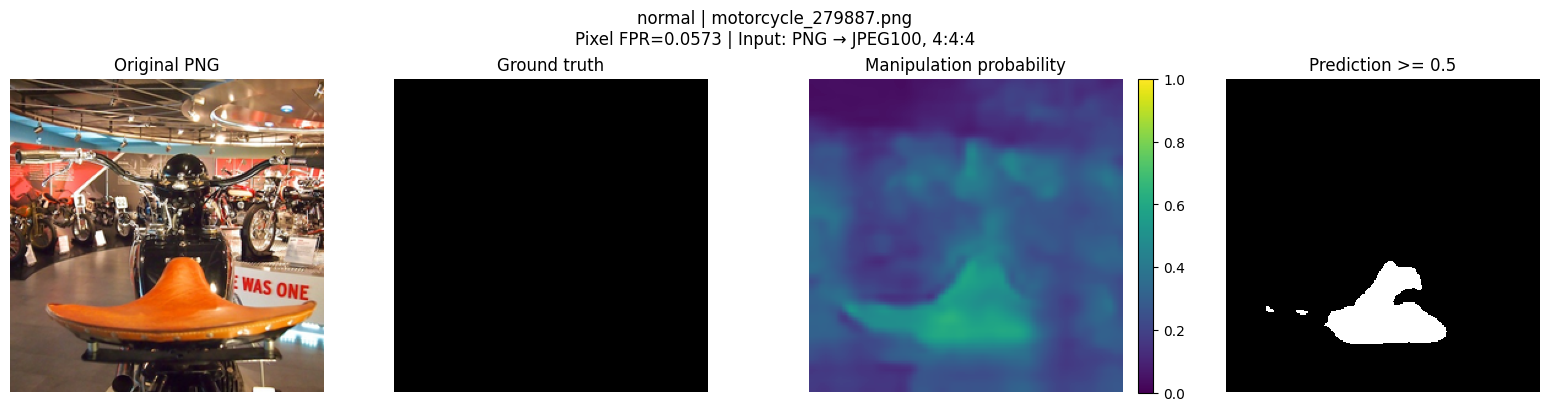

TP·FP·FN·TN: 0 3757 0 61779
최대 조작 확률: 0.6388659477233887
예측 조작 영역 비율: 0.0573272705078125


In [20]:
import numpy as np
import matplotlib.pyplot as plt

vis_rng = np.random.default_rng(42)
vis_records = []
vis_threshold = 0.5

for kind in ("manipulated", "normal"):
    candidates = [r for r in input_records if r["dataset"] == "CocoGlide" and r["kind"] == kind]
    indices = vis_rng.choice(len(candidates), size=2, replace=False)
    vis_records.extend(candidates[int(i)] for i in indices)

for record in vis_records:
    vis_rgb = preprocessing.load_rgb(record["image_path"])

    if record["kind"] == "manipulated":
        vis_mask = preprocessing.load_binary_mask(record["mask_path"], foreground_value=255)
    else:
        vis_mask = np.zeros(vis_rgb.shape[:2], dtype=np.uint8)

    vis_probability = detector.predict_proba(record["input_path"])
    vis_prediction = (vis_probability >= vis_threshold).astype(np.uint8)

    tp, fp, fn, tn = evaluation.confusion_counts(vis_mask, vis_prediction)

    if record["kind"] == "manipulated":
        f1 = evaluation.pixel_f1(tp, fp, fn)
        iou_score = evaluation.iou(tp, fp, fn)
        score_text = f"F1={f1:.4f}, IoU={iou_score:.4f}"
    else:
        fpr = evaluation.false_positive_rate(fp, tn)
        score_text = f"Pixel FPR={fpr:.4f}"

    fig, axes = plt.subplots(1, 4, figsize=(16, 4), constrained_layout=True)

    axes[0].imshow(vis_rgb)
    axes[0].set_title("Original PNG")

    axes[1].imshow(vis_mask, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    axes[1].set_title("Ground truth")

    heatmap = axes[2].imshow(vis_probability, cmap="viridis", vmin=0, vmax=1, interpolation="nearest")
    axes[2].set_title("Manipulation probability")
    fig.colorbar(heatmap, ax=axes[2], fraction=0.046, pad=0.04)

    axes[3].imshow(vis_prediction, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    axes[3].set_title(f"Prediction >= {vis_threshold}")

    for ax in axes:
        ax.axis("off")

    fig.suptitle(f"{record['kind']} | {record['image_path'].name}\n{score_text} | Input: PNG → JPEG100, 4:4:4")
    plt.show()

    print("TP·FP·FN·TN:", tp, fp, fn, tn)
    print("최대 조작 확률:", float(vis_probability.max()))
    print("예측 조작 영역 비율:", float(vis_prediction.mean()))

원본 ID: 41932
조작 이미지: 41932_1.jpg


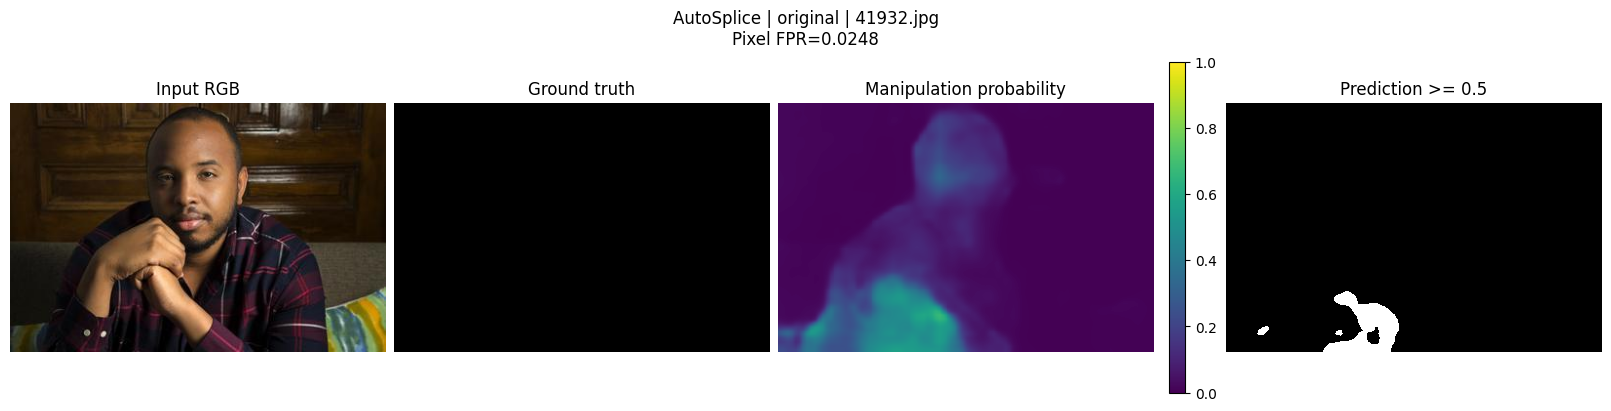

TP·FP·FN·TN: 0 2447 0 96369
최대 조작 확률: 0.671282172203064
예측 조작 영역 비율: 0.024763196243523317


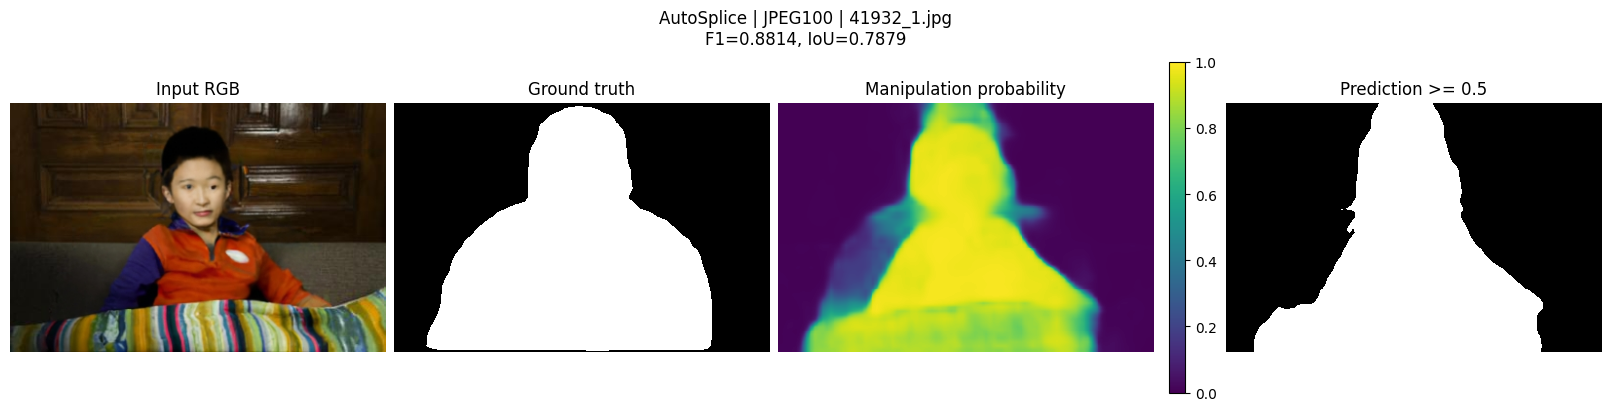

TP·FP·FN·TN: 37862 1488 8705 50761
최대 조작 확률: 0.991958737373352
예측 조작 영역 비율: 0.3982148639896373


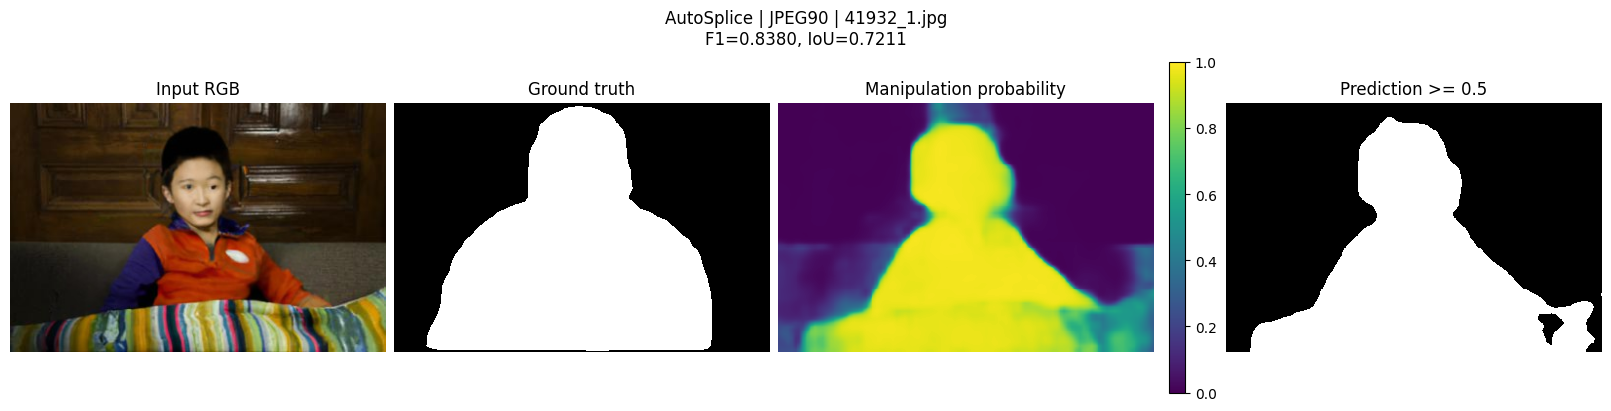

TP·FP·FN·TN: 35654 2877 10913 49372
최대 조작 확률: 0.9898172616958618
예측 조작 영역 비율: 0.38992673251295334


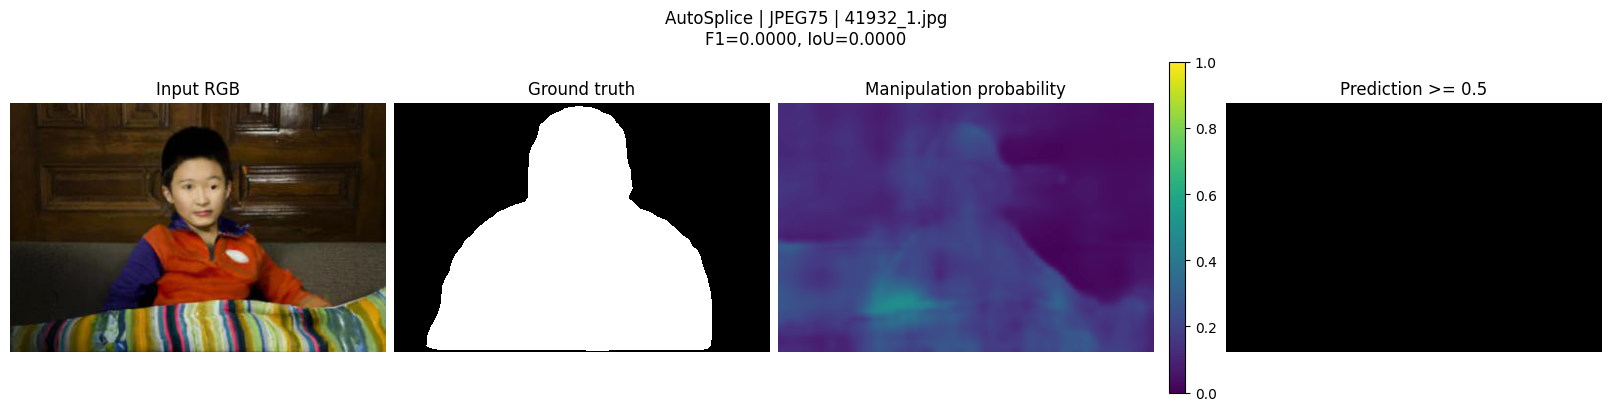

TP·FP·FN·TN: 0 0 46567 52249
최대 조작 확률: 0.4963494837284088
예측 조작 영역 비율: 0.0


In [21]:
auto_rng = np.random.default_rng(42)

candidates = [r for r in input_records if r["dataset"] == "AutoSplice" and r["variant"] == "JPEG100"]
chosen = candidates[int(auto_rng.integers(len(candidates)))]

normal_record = next(
    r for r in input_records
    if r["dataset"] == "AutoSplice" and r["kind"] == "normal"
    and r["original_id"] == chosen["original_id"]
)

same_image = {
    r["variant"]: r for r in input_records
    if r["dataset"] == "AutoSplice" and r["kind"] == "manipulated"
    and r["image_path"].name == chosen["image_path"].name
}

auto_records = [normal_record] + [same_image[f"JPEG{q}"] for q in (100, 90, 75)]
vis_threshold = 0.5

print("원본 ID:", chosen["original_id"])
print("조작 이미지:", chosen["image_path"].name)

for record in auto_records:
    vis_rgb = preprocessing.load_rgb(record["image_path"])

    if record["kind"] == "manipulated":
        vis_mask = preprocessing.load_binary_mask(record["mask_path"], foreground_value=255)
    else:
        vis_mask = np.zeros(vis_rgb.shape[:2], dtype=np.uint8)

    vis_probability = detector.predict_proba(record["input_path"])
    vis_prediction = (vis_probability >= vis_threshold).astype(np.uint8)

    tp, fp, fn, tn = evaluation.confusion_counts(vis_mask, vis_prediction)

    if record["kind"] == "manipulated":
        f1 = evaluation.pixel_f1(tp, fp, fn)
        iou_score = evaluation.iou(tp, fp, fn)
        score_text = f"F1={f1:.4f}, IoU={iou_score:.4f}"
    else:
        fpr = evaluation.false_positive_rate(fp, tn)
        score_text = f"Pixel FPR={fpr:.4f}"

    fig, axes = plt.subplots(1, 4, figsize=(16, 4), constrained_layout=True)

    axes[0].imshow(vis_rgb)
    axes[0].set_title("Input RGB")

    axes[1].imshow(vis_mask, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    axes[1].set_title("Ground truth")

    heatmap = axes[2].imshow(vis_probability, cmap="viridis", vmin=0, vmax=1, interpolation="nearest")
    axes[2].set_title("Manipulation probability")
    fig.colorbar(heatmap, ax=axes[2], fraction=0.046, pad=0.04)

    axes[3].imshow(vis_prediction, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    axes[3].set_title(f"Prediction >= {vis_threshold}")

    for ax in axes:
        ax.axis("off")

    fig.suptitle(f"AutoSplice | {record['variant']} | {record['image_path'].name}\n{score_text}")
    plt.show()

    print("TP·FP·FN·TN:", tp, fp, fn, tn)
    print("최대 조작 확률:", float(vis_probability.max()))
    print("예측 조작 영역 비율:", float(vis_prediction.mean()))

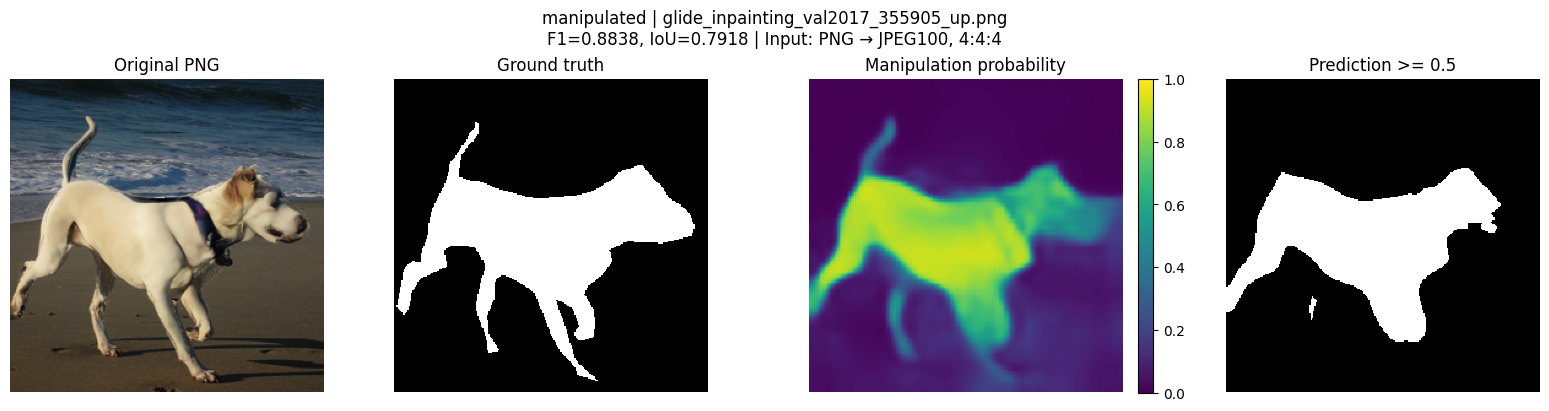

TP·FP·FN·TN: 13813 956 2675 48092
최대 조작 확률: 0.9305394291877747
예측 조작 영역 비율: 0.2253570556640625


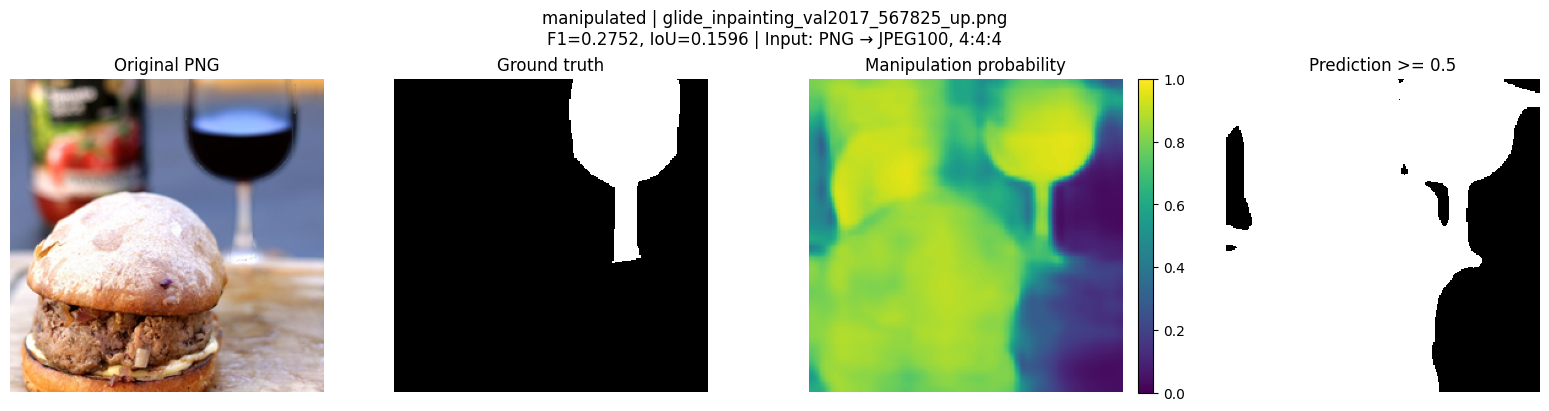

TP·FP·FN·TN: 7949 41738 125 15724
최대 조작 확률: 0.9601176977157593
예측 조작 영역 비율: 0.7581634521484375


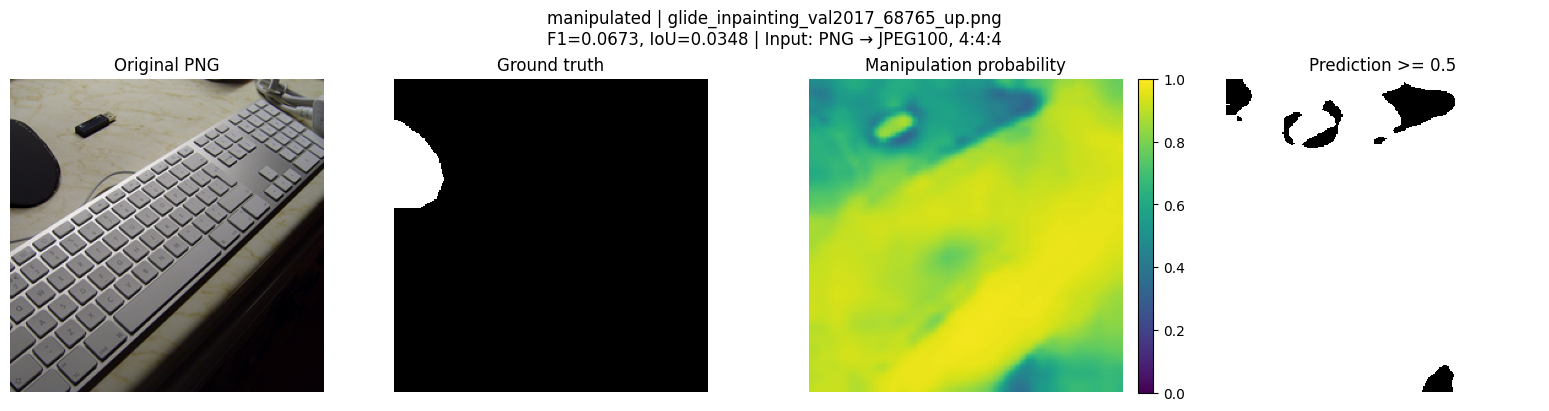

TP·FP·FN·TN: 2180 60466 0 2890
최대 조작 확률: 0.9826855659484863
예측 조작 영역 비율: 0.955902099609375


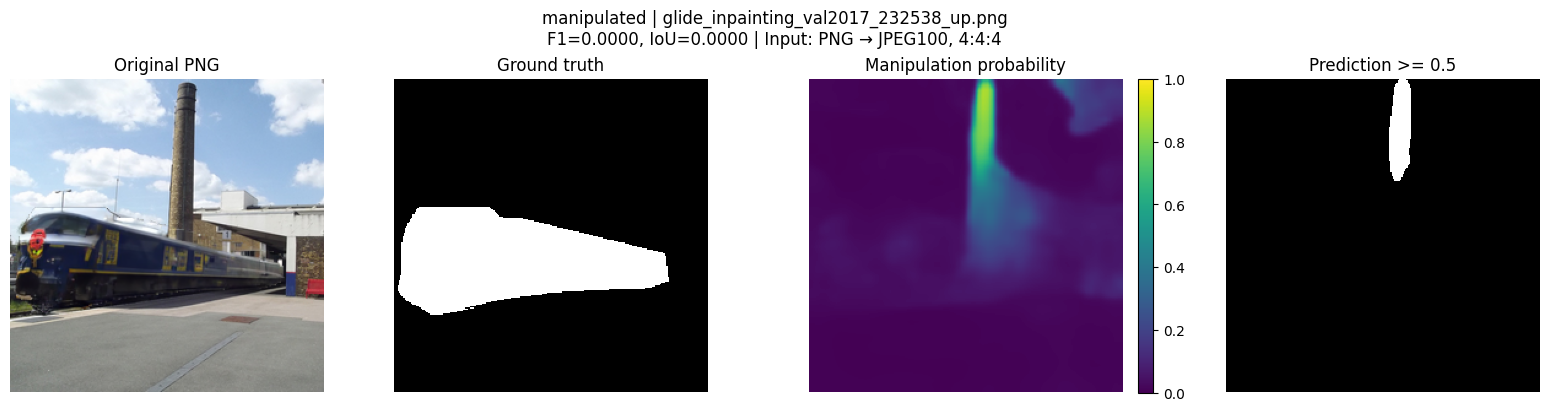

TP·FP·FN·TN: 0 1232 12881 51423
최대 조작 확률: 0.8778889179229736
예측 조작 영역 비율: 0.018798828125


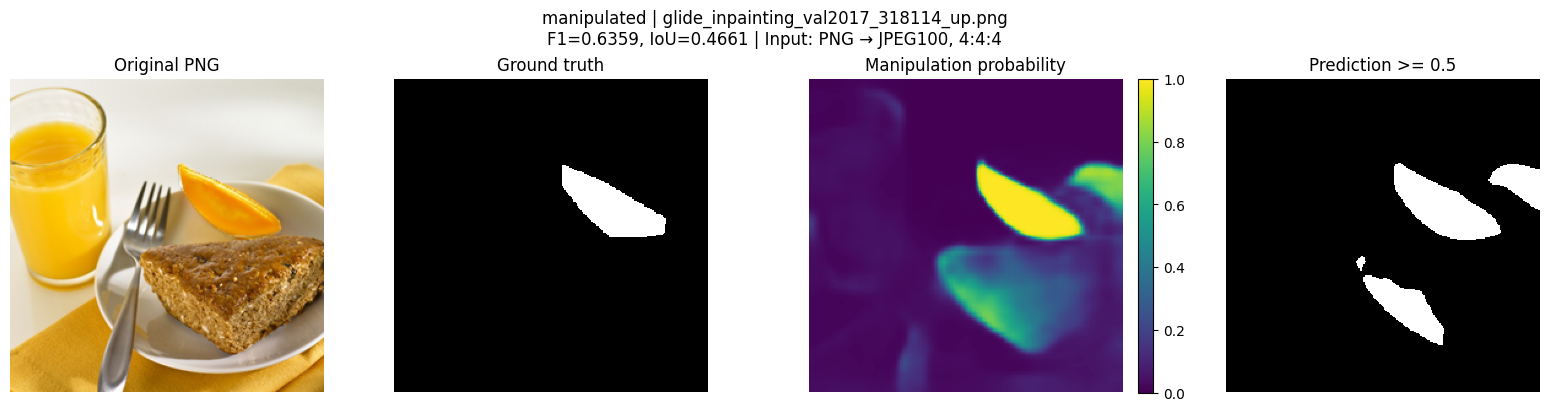

TP·FP·FN·TN: 2526 2855 38 60117
최대 조작 확률: 0.9991794228553772
예측 조작 영역 비율: 0.0821075439453125


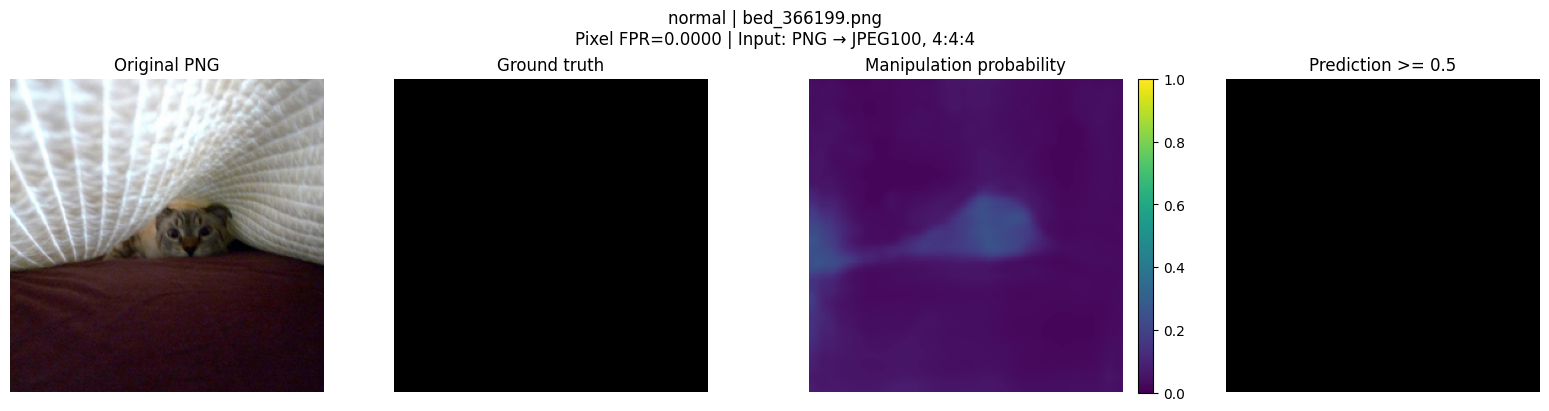

TP·FP·FN·TN: 0 0 0 65536
최대 조작 확률: 0.2581770420074463
예측 조작 영역 비율: 0.0


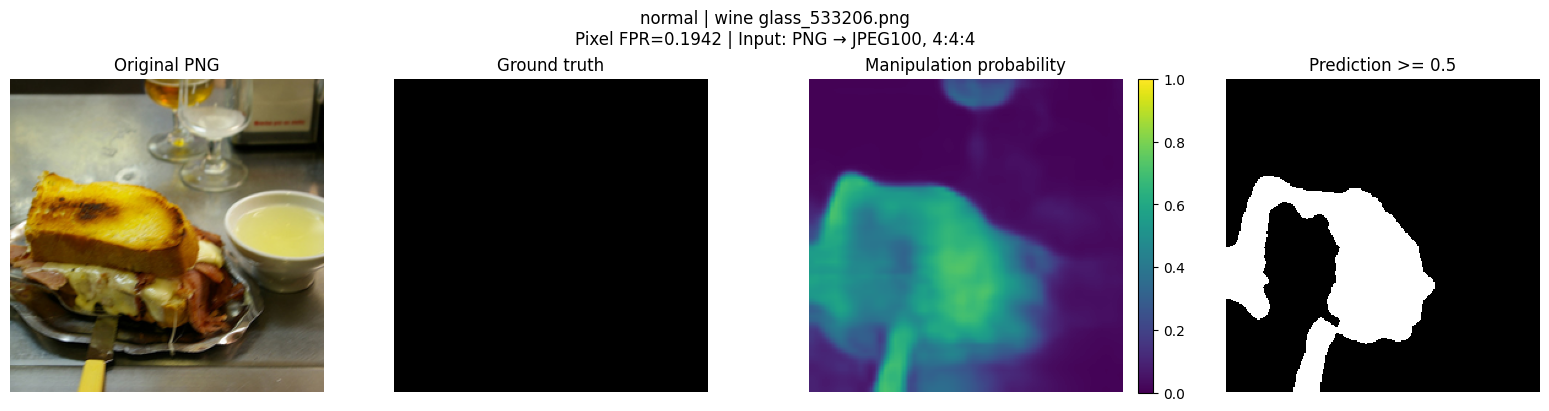

TP·FP·FN·TN: 0 12727 0 52809
최대 조작 확률: 0.7299731373786926
예측 조작 영역 비율: 0.1941986083984375


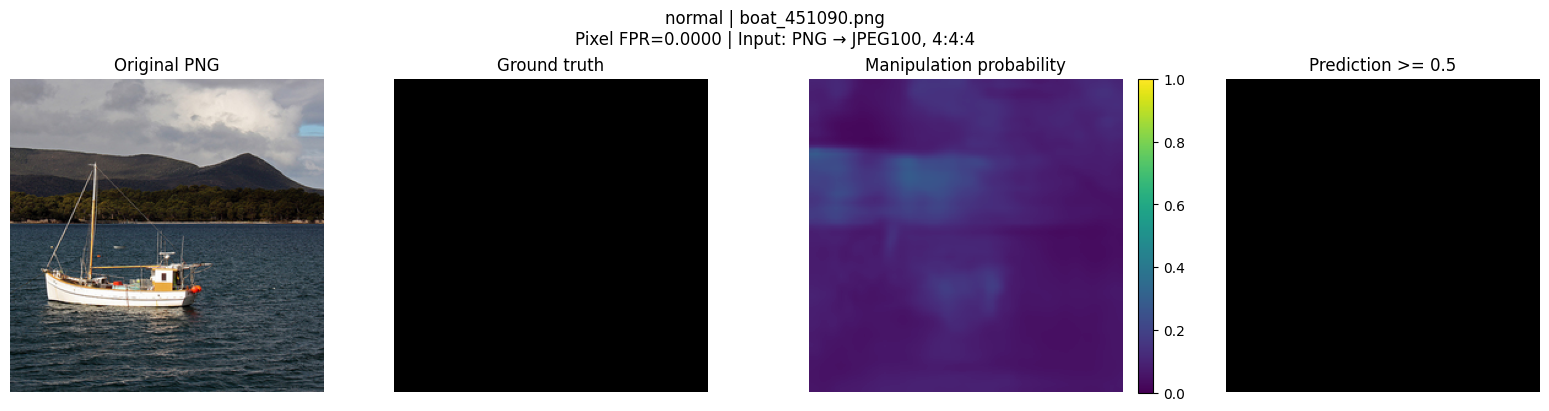

TP·FP·FN·TN: 0 0 0 65536
최대 조작 확률: 0.2878774106502533
예측 조작 영역 비율: 0.0


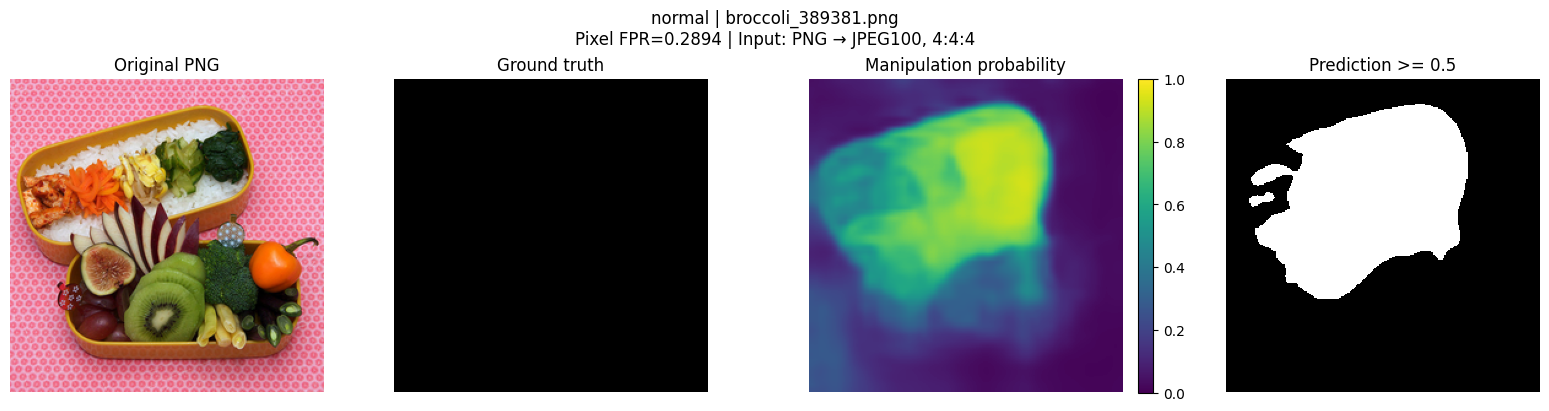

TP·FP·FN·TN: 0 18965 0 46571
최대 조작 확률: 0.9372689723968506
예측 조작 영역 비율: 0.2893829345703125


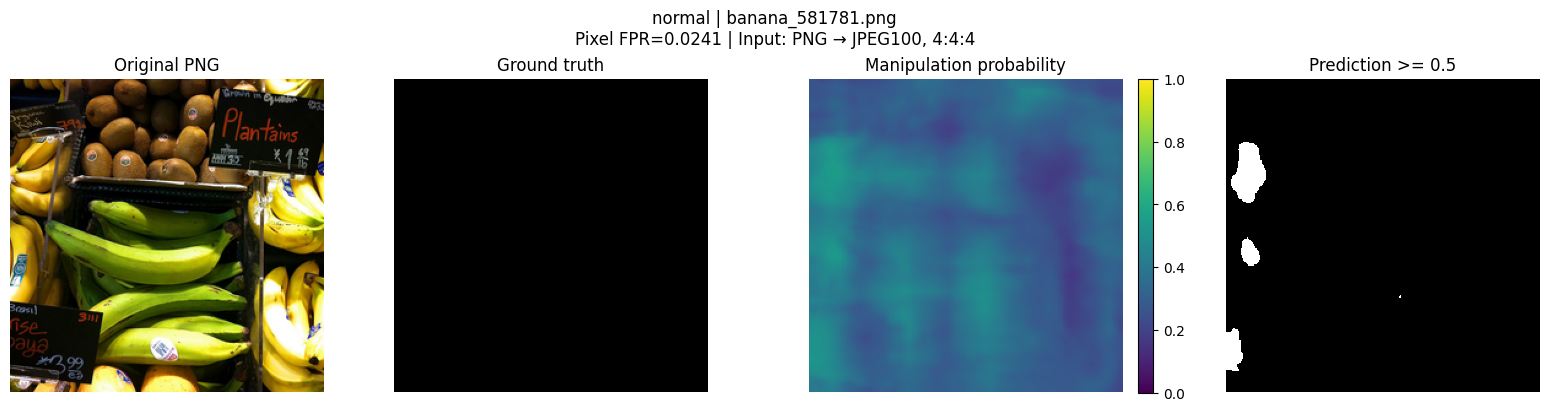

TP·FP·FN·TN: 0 1577 0 63959
최대 조작 확률: 0.5479946136474609
예측 조작 영역 비율: 0.0240631103515625


In [22]:
extra_rng = np.random.default_rng(43)
seen_paths = {r["image_path"] for r in vis_records}
extra_records = []

for kind in ("manipulated", "normal"):
    candidates = [
        r for r in input_records
        if r["dataset"] == "CocoGlide" and r["kind"] == kind
        and r["image_path"] not in seen_paths
    ]
    indices = extra_rng.choice(len(candidates), size=5, replace=False)
    extra_records.extend(candidates[int(i)] for i in indices)

vis_threshold = 0.5

for record in extra_records:
    vis_rgb = preprocessing.load_rgb(record["image_path"])

    if record["kind"] == "manipulated":
        vis_mask = preprocessing.load_binary_mask(record["mask_path"], foreground_value=255)
    else:
        vis_mask = np.zeros(vis_rgb.shape[:2], dtype=np.uint8)

    vis_probability = detector.predict_proba(record["input_path"])
    vis_prediction = (vis_probability >= vis_threshold).astype(np.uint8)

    tp, fp, fn, tn = evaluation.confusion_counts(vis_mask, vis_prediction)

    if record["kind"] == "manipulated":
        f1 = evaluation.pixel_f1(tp, fp, fn)
        iou_score = evaluation.iou(tp, fp, fn)
        score_text = f"F1={f1:.4f}, IoU={iou_score:.4f}"
    else:
        fpr = evaluation.false_positive_rate(fp, tn)
        score_text = f"Pixel FPR={fpr:.4f}"

    fig, axes = plt.subplots(1, 4, figsize=(16, 4), constrained_layout=True)

    axes[0].imshow(vis_rgb)
    axes[0].set_title("Original PNG")

    axes[1].imshow(vis_mask, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    axes[1].set_title("Ground truth")

    heatmap = axes[2].imshow(vis_probability, cmap="viridis", vmin=0, vmax=1, interpolation="nearest")
    axes[2].set_title("Manipulation probability")
    fig.colorbar(heatmap, ax=axes[2], fraction=0.046, pad=0.04)

    axes[3].imshow(vis_prediction, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    axes[3].set_title(f"Prediction >= {vis_threshold}")

    for ax in axes:
        ax.axis("off")

    fig.suptitle(f"{record['kind']} | {record['image_path'].name}\n{score_text} | Input: PNG → JPEG100, 4:4:4")
    plt.show()

    print("TP·FP·FN·TN:", tp, fp, fn, tn)
    print("최대 조작 확률:", float(vis_probability.max()))
    print("예측 조작 영역 비율:", float(vis_prediction.mean()))

    vis_records.append(record)